# Lesson 6 · Seeing Your Data: Matplotlib
### Line, bar, histogram, scatter and box plots: and how to make charts that tell the truth

| | |
|---|---|
| **Type** | SOLUTIONS 06 |
| **Time** | about 120 minutes |
| **Level** | Beginner → Intermediate |
| **Prerequisites** | Lessons 3–5 |

**By the end of this notebook you will be able to:**

- Explain why we *always* plot, using Anscombe's quartet
- Use the object-oriented Matplotlib interface: `fig, ax = plt.subplots()`
- Draw line, bar, histogram, scatter and box plots from pandas data
- Customise titles, labels, legends, annotations, shaded regions and date axes
- Build multi-panel figures, dual-axis charts and save to file
- Choose the right chart for a question, and spot misleading charts

## 🛠️ Setup (identical to the lesson notebook)

In [1]:

import sys; sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from course_utils import DATA_DIR, check, check_plot

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (9, 4.5), "figure.dpi": 100, "axes.titlesize": 13, "axes.titleweight": "bold",
                     "axes.labelsize": 11, "axes.spines.top": False, "axes.spines.right": False})

prices = pd.read_csv(DATA_DIR / "market_prices_clean.csv", parse_dates=["date"])
prices["year"] = prices["date"].dt.year
prices["month"] = prices["date"].dt.month
print("Setup complete ✔  prices:", prices.shape)


Setup complete ✔  prices: (15048, 11)


### 🎨 Problem 6.1: Maize at Nakuru over time

Draw a **line chart** of the weekly **Maize** price at **Nakuru Municipal Market** against date (sorted by date). Add a title, an x-label and a y-label (with units).

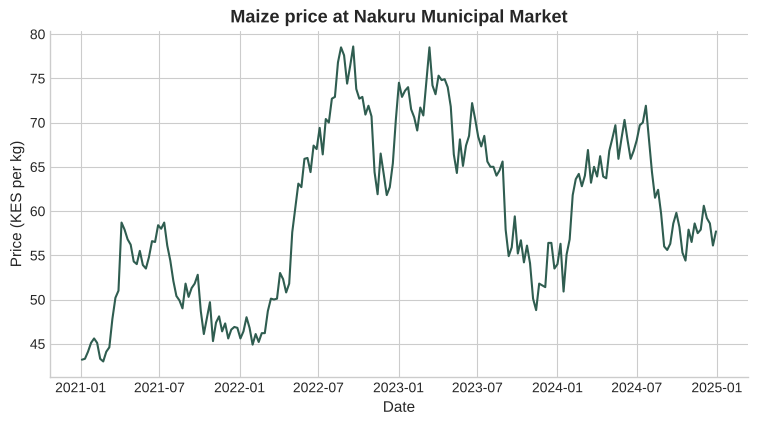

✅ 06-p1: your chart has the essentials. Now ask yourself: would a stranger understand it in 10 seconds?


True

In [2]:
d = prices[(prices["crop"] == "Maize") & (prices["market"] == "Nakuru Municipal Market")].sort_values("date")
fig, ax = plt.subplots()
ax.plot(d["date"], d["price_kes_per_kg"], color="#2F5D50")
ax.set_title("Maize price at Nakuru Municipal Market")
ax.set_xlabel("Date"); ax.set_ylabel("Price (KES per kg)")
plt.show()

check_plot(ax, n_lines=1, name='06-p1')

### 🎨 Problem 6.2: Three counties, one chart

Plot the **monthly average Tomato price** for **Nairobi, Mombasa and Kisumu** as **three lines** on one chart (legend required, plus title and axis labels).

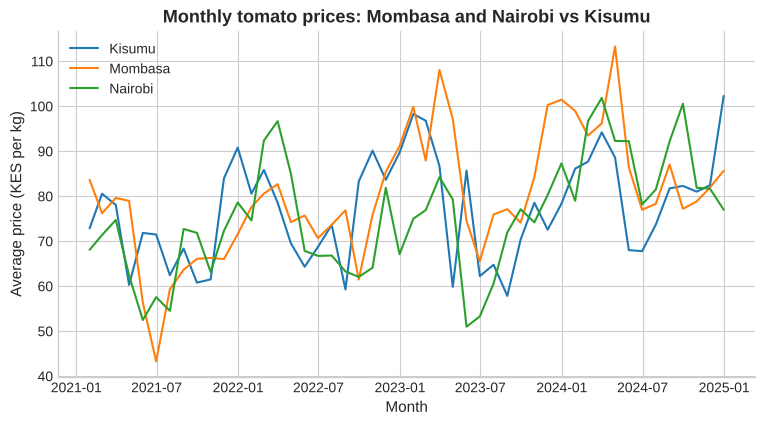

✅ 06-p2: your chart has the essentials. Now ask yourself: would a stranger understand it in 10 seconds?


True

In [3]:
t = prices[(prices["crop"] == "Tomatoes") & (prices["county"].isin(["Nairobi", "Mombasa", "Kisumu"]))]
fig, ax = plt.subplots()
for county, g in t.groupby("county"):
    m = g.set_index("date")["price_kes_per_kg"].resample("ME").mean()
    ax.plot(m.index, m.values, label=county)
ax.set_title("Monthly tomato prices: Mombasa and Nairobi vs Kisumu")
ax.set_xlabel("Month"); ax.set_ylabel("Average price (KES per kg)")
ax.legend()
plt.show()

check_plot(ax, n_lines=3, legend=True, name='06-p2')

### 🎨 Problem 6.3: Crop price league table

Draw a **horizontal bar chart** of the **mean price per crop**, sorted from cheapest to dearest, with a title and an x-label.

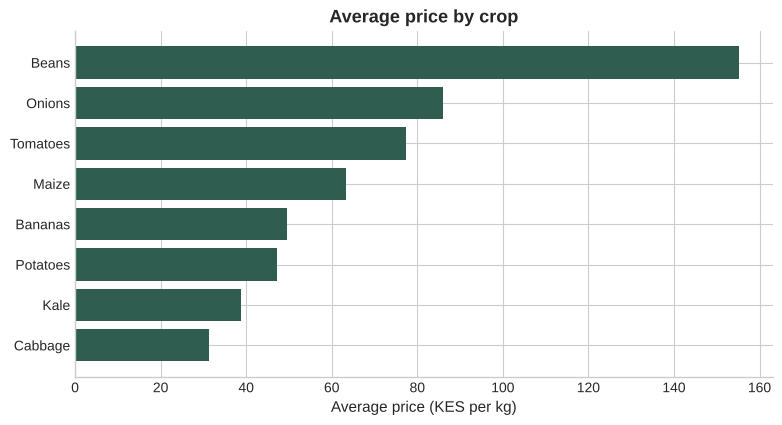

✅ 06-p3: your chart has the essentials. Now ask yourself: would a stranger understand it in 10 seconds?


True

In [4]:
avg = prices.groupby("crop")["price_kes_per_kg"].mean().sort_values()
fig, ax = plt.subplots()
ax.barh(avg.index, avg.values, color="#2F5D50")
ax.set_title("Average price by crop")
ax.set_xlabel("Average price (KES per kg)")
plt.show()

check_plot(ax, min_bars=8, ylabel=False, name='06-p3')

### 🎨 Problem 6.4: Beans: mean vs median

Draw a **histogram (20 bins)** of all **Beans** prices. Add **two vertical lines**: one for the mean, one for the median (different styles), plus title and axis labels.

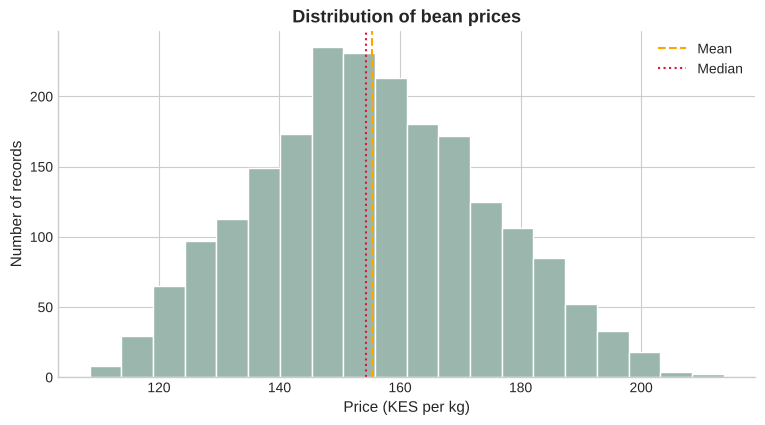

✅ 06-p4: your chart has the essentials. Now ask yourself: would a stranger understand it in 10 seconds?


True

In [5]:
b = prices.loc[prices["crop"] == "Beans", "price_kes_per_kg"]
fig, ax = plt.subplots()
ax.hist(b, bins=20, color="#9bb7ad", edgecolor="white")
ax.axvline(b.mean(), color="orange", linestyle="--", label="Mean")
ax.axvline(b.median(), color="crimson", linestyle=":", label="Median")
ax.set_title("Distribution of bean prices")
ax.set_xlabel("Price (KES per kg)"); ax.set_ylabel("Number of records")
ax.legend()
plt.show()

check_plot(ax, n_lines=2, min_bars=20, name='06-p4')

### 🎨 Problem 6.5: Does volume move price?

Draw a **scatter plot** of weekly **volume (tonnes, x)** against **price (KES/kg, y)** for **Tomatoes at Wakulima Market**, with title and axis labels.

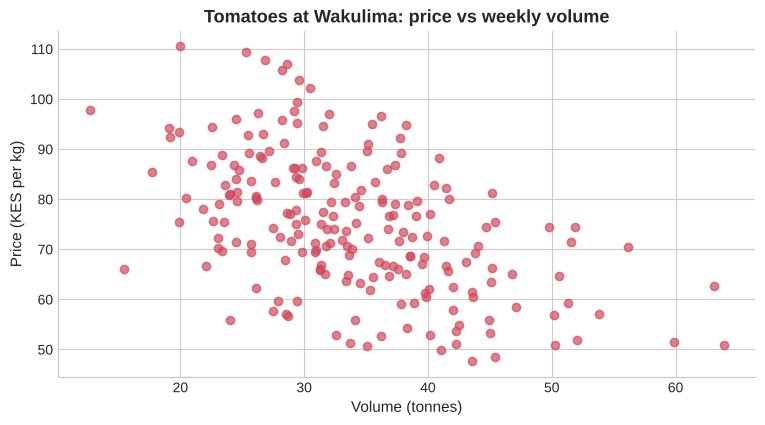

✅ 06-p5: your chart has the essentials. Now ask yourself: would a stranger understand it in 10 seconds?


True

In [6]:
t = prices[(prices["crop"] == "Tomatoes") & (prices["market"] == "Wakulima Market")]
fig, ax = plt.subplots()
ax.scatter(t["volume_kg"] / 1000, t["price_kes_per_kg"], alpha=0.7, color="#d1495b")
ax.set_title("Tomatoes at Wakulima: price vs weekly volume")
ax.set_xlabel("Volume (tonnes)"); ax.set_ylabel("Price (KES per kg)")
plt.show()

check_plot(ax, min_points=100, name='06-p5')

### 🎨 Problem 6.6: Which crop is most variable?

Draw a **box plot** of price for every crop (one box per crop, in alphabetical order), with the crop names on the x-axis, a title and a y-label.

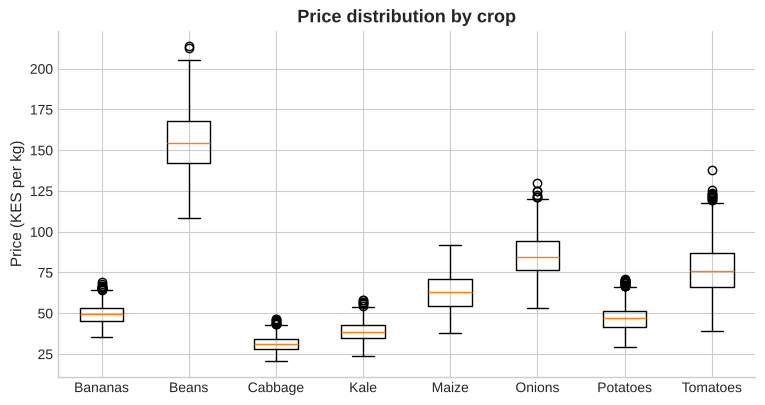

✅ 06-p6: your chart has the essentials. Now ask yourself: would a stranger understand it in 10 seconds?


True

In [7]:
crops = sorted(prices["crop"].unique())
data = [prices.loc[prices["crop"] == c, "price_kes_per_kg"] for c in crops]
fig, ax = plt.subplots()
ax.boxplot(data)
ax.set_xticklabels(crops)
ax.set_title("Price distribution by crop")
ax.set_ylabel("Price (KES per kg)")
plt.show()

check_plot(ax, min_lines=8, xlabel=False, name='06-p6')

### 🎨 Problem 6.7: A 2×2 dashboard

Create a figure with a **2×2 grid** of axes (`axes`). Fill it with the national weekly average price of **Maize, Beans, Onions, Potatoes** (one crop per panel, line plots). Give **each panel a title** and a y-label. Finally set `ax = axes[1, 1]` so the checker can inspect the last panel.

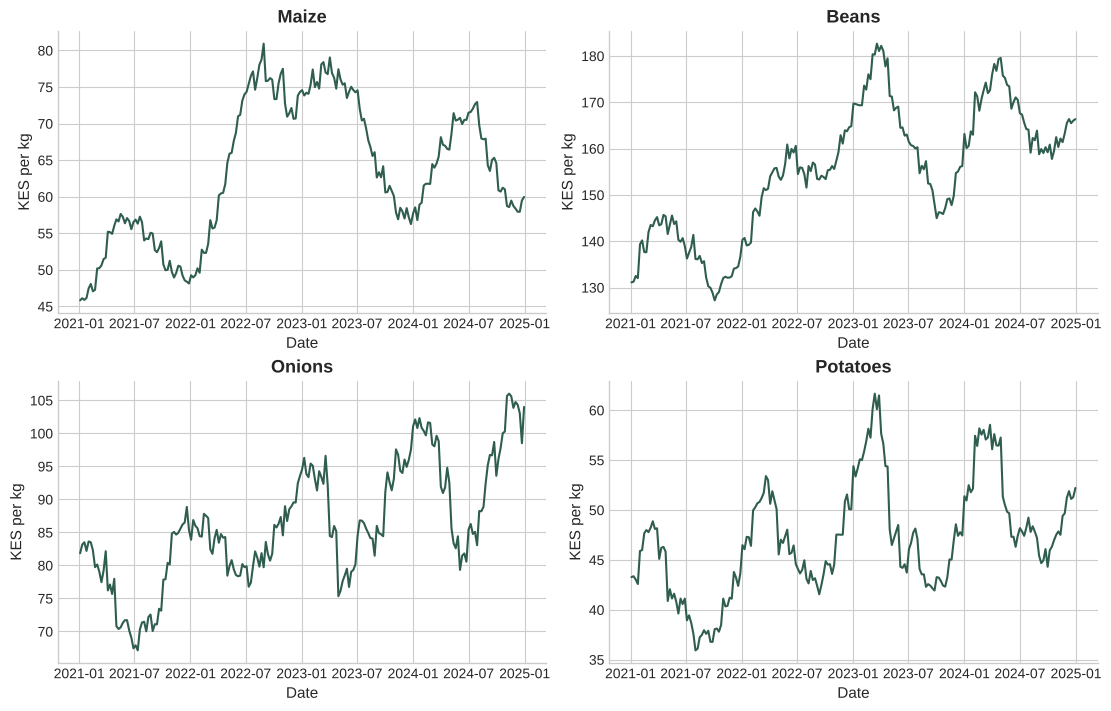

✅ 06-p7: your chart has the essentials. Now ask yourself: would a stranger understand it in 10 seconds?


True

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
for a, crop in zip(axes.flat, ["Maize", "Beans", "Onions", "Potatoes"]):
    g = prices[prices["crop"] == crop].groupby("date")["price_kes_per_kg"].mean()
    a.plot(g.index, g.values, color="#2F5D50")
    a.set_title(crop); a.set_xlabel("Date"); a.set_ylabel("KES per kg")
ax = axes[1, 1]
plt.show()

check_plot(ax, n_lines=1, name='06-p7')

### ✍️ Problem 6.8: Critique this chart

Someone shows you a **3-D pie chart** with 8 slices (one per crop) sized by *average price*, a rainbow colour scheme, no title, and no numbers. List **at least four problems**, and say which chart from the guide you would replace it with, and what its title would be.

**Model answer**

Problems: (1) 3-D distorts slice sizes; (2) eight slices are impossible to compare by angle/area; (3) no title or message; (4) no numbers or units; (5) rainbow colours imply no order and aren't colour-blind safe; (6) a pie implies *parts of a whole*, but average prices don't add up to anything meaningful. Replace with a **sorted horizontal bar chart** from zero with value labels. Title: *'Beans are the priciest crop (≈155 KES/kg); cabbage the cheapest (≈31)'*.